<a href="https://colab.research.google.com/github/DanyRE4020/Concentracion_IA_avanzada/blob/main/Notebook7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Notebook 7 — Regresión lineal de O3 y diagnóstico de supuestos



In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
data_2026 = pd.read_csv('/content/contaminantes_2026.csv', sep=',',skiprows=9,encoding="utf-8")
data_2026.columns = ["date", "id_station", "id_parameter", "value", "unit"]
data_2026.head()


,date,id_station,id_parameter,value,unit
0,2026-01-01 00:00:00,ACO,CO,NaN,15
1,2026-01-01 00:00:00,ACO,NO,NaN,1
2,2026-01-01 00:00:00,ACO,NO2,NaN,1
3,2026-01-01 00:00:00,ACO,NOX,NaN,1
4,2026-01-01 00:00:00,ACO,O3,NaN,1


In [9]:

def _clean_name(x):
    return (str(x).strip().lower()
            .replace('á','a').replace('é','e').replace('í','i')
            .replace('ó','o').replace('ú','u').replace('ñ','n'))

def _find_col(cols, candidates):
    normalized = {_clean_name(c): c for c in cols}
    for cand in candidates:
        if cand in normalized:
            return normalized[cand]
    for c in cols:
        cn = _clean_name(c)
        if any(cand in cn for cand in candidates):
            return c
    return None

def make_wide(df):
    d = df.copy()
    d.columns = [str(c).strip() for c in d.columns]

    station_col = _find_col(d.columns, ['id_station','station','estacion','cve_est','id_estacion'])
    date_col = _find_col(d.columns, ['date','fecha','datetime','timestamp'])
    hour_col = _find_col(d.columns, ['hour','hora'])
    param_col = _find_col(d.columns, ['id_parameter','parameter','parametro','contaminant','contaminante'])
    value_col = _find_col(d.columns, ['value','valor','concentration','concentracion'])

    if station_col is None or date_col is None:
        raise ValueError(f'No pude detectar las columnas de estación/fecha. Columnas: {list(d.columns)}')

    base_date = pd.to_datetime(d[date_col], errors='coerce')
    if hour_col is not None and _clean_name(hour_col) not in ['datetime','timestamp']:
        h = pd.to_numeric(d[hour_col], errors='coerce')
        extra_day = (h == 24).astype(int)
        h = h.where(h != 24, 0)
        d['datetime'] = base_date.dt.normalize() + pd.to_timedelta(extra_day, unit='D') + pd.to_timedelta(h, unit='h')
    else:
        d['datetime'] = base_date

    d['id_station'] = d[station_col].astype(str).str.strip().str.upper()

    if param_col is not None and value_col is not None:
        d['pollutant'] = d[param_col].astype(str).str.strip().str.upper()
        d['value_num'] = pd.to_numeric(d[value_col], errors='coerce')
        wide = (d.pivot_table(index=['datetime','id_station'], columns='pollutant', values='value_num', aggfunc='mean')
                  .reset_index())
    else:
        wide = d.copy()
        fixed = {}
        for c in wide.columns:
            if c not in ['datetime','id_station']:
                fixed[c] = str(c).strip().upper()
        wide = wide.rename(columns=fixed)

    ren = {}
    for c in wide.columns:
        cu = str(c).upper().replace(' ', '').replace('_','').replace('.','')
        if cu in ['PM25','PM2,5']:
            ren[c] = 'PM2.5'
        elif cu == 'PM10':
            ren[c] = 'PM10'
        elif cu == 'PMCO':
            ren[c] = 'PMCO'
        elif cu in ['NOX','NO2','NO','CO','O3','SO2']:
            ren[c] = cu
    wide = wide.rename(columns=ren)
    return wide.sort_values(['datetime','id_station']).reset_index(drop=True)

wide_raw = make_wide(data_2026)
pollutants = [c for c in ['CO','NO','NO2','NOX','O3','PM10','PM2.5','PMCO','SO2'] if c in wide_raw.columns]
for c in pollutants:
    wide_raw[c] = pd.to_numeric(wide_raw[c], errors='coerce')

print('Contaminantes encontrados:', pollutants)
print('Número de estaciones:', wide_raw['id_station'].nunique())
wide_raw.head()


Contaminantes encontrados: ['CO', 'NO', 'NO2', 'NOX', 'O3', 'PM10', 'PM2.5', 'PMCO', 'SO2']
Número de estaciones: 31


pollutant,datetime,id_station,CO,NO,NO2,NOX,O3,PM10,PM2.5,PMCO,SO2
0,2026-01-01,AJM,0.74,2.0,26.0,28.0,19.0,67.0,53.0,14.0,28.0
1,2026-01-01,ATI,0.70,2.0,21.0,23.0,18.0,90.0,NaN,NaN,22.0
2,2026-01-01,BJU,1.07,NaN,32.0,NaN,17.0,62.0,41.0,21.0,3.0
3,2026-01-01,CAM,NaN,7.0,44.0,52.0,4.0,57.0,49.0,8.0,25.0
4,2026-01-01,CCA,1.12,1.0,32.0,33.0,13.0,NaN,27.0,NaN,3.0


## Selección de estación y limpieza

In [10]:

STATION = 'MER'
if STATION not in set(wide_raw['id_station']):
    print(f'{STATION} no aparece; se usará la primera estación disponible.')
    STATION = wide_raw['id_station'].dropna().iloc[0]

vars_modelo = ['O3','NO','NO2','NOX','CO']
missing = [c for c in vars_modelo if c not in wide_raw.columns]
if missing:
    raise ValueError(f'Faltan columnas requeridas: {missing}')

data = wide_raw.loc[wide_raw['id_station'].eq(STATION), ['datetime','id_station'] + vars_modelo].copy()
for c in vars_modelo:
    data.loc[data[c] < 0, c] = np.nan
model_df = data.dropna(subset=vars_modelo).copy()

print('Estación:', STATION)
print('Filas antes de eliminar faltantes:', len(data))
print('Filas completas usadas:', len(model_df))
model_df.head()


Estación: MER
Filas antes de eliminar faltantes: 5001
Filas completas usadas: 4639


pollutant,datetime,id_station,O3,NO,NO2,NOX,CO
13,2026-01-01 00:00:00,MER,7.0,7.0,41.0,47.0,1.05
38,2026-01-01 01:00:00,MER,3.0,13.0,45.0,58.0,1.31
63,2026-01-01 02:00:00,MER,3.0,27.0,48.0,76.0,1.63
88,2026-01-01 03:00:00,MER,3.0,35.0,44.0,79.0,1.43
113,2026-01-01 04:00:00,MER,4.0,12.0,44.0,56.0,1.22


## a) Regresión lineal para predecir O3

In [11]:

X = model_df[['NO','NO2','NOX','CO']]
y = model_df['O3']
Xc = sm.add_constant(X)
model = sm.OLS(y, Xc).fit()

print(model.summary())
print('R² =', round(model.rsquared, 4))
pd.DataFrame({'coeficiente': model.params, 'p_value': model.pvalues})


                            OLS Regression Results                            
Dep. Variable:                     O3   R-squared:                       0.254
Model:                            OLS   Adj. R-squared:                  0.254
Method:                 Least Squares   F-statistic:                     394.8
Date:                Sun, 04 Oct 2026   Prob (F-statistic):          4.76e-293
Time:                        23:06:12   Log-Likelihood:                -21912.
No. Observations:                4639   AIC:                         4.383e+04
Df Residuals:                    4634   BIC:                         4.387e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         56.3540      1.066     52.853      0.0

,coeficiente,p_value
const,56.354044,0.000000e+00
NO,1.208539,1.264881e-01
NO2,0.687055,3.855172e-01
NOX,-1.541916,5.127578e-02
CO,14.294903,5.704032e-12


## b) VIF de cada variable

In [12]:

X_vif = sm.add_constant(X)
vif = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif


,variable,VIF
0,const,1.000000
1,NO,5063.595655
2,NO2,871.942799
3,NOX,8104.930265
4,CO,5.606601


## c) Residuos vs. predichos y Breusch–Pagan

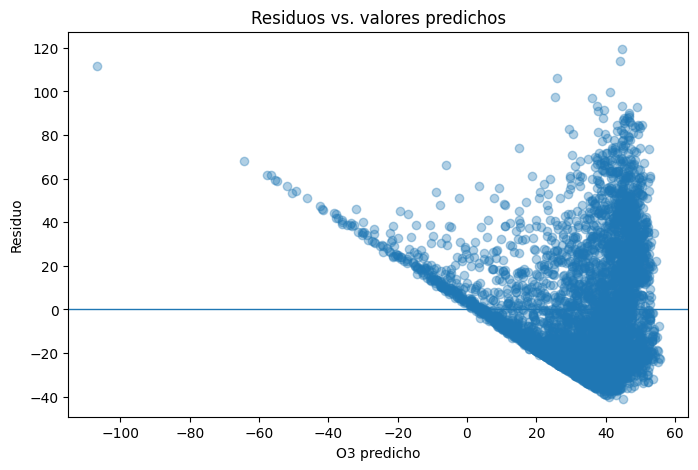

,0
LM statistic,9.146962e+01
LM p-value,6.416021e-19
F statistic,2.330222e+01
F p-value,4.265777e-19


Conclusión: hay evidencia de heterocedasticidad (α=0.05).


In [13]:

from statsmodels.stats.diagnostic import het_breuschpagan

fitted = model.fittedvalues
resid = model.resid

plt.figure(figsize=(8,5))
plt.scatter(fitted, resid, alpha=0.35)
plt.axhline(0, linewidth=1)
plt.xlabel('O3 predicho')
plt.ylabel('Residuo')
plt.title('Residuos vs. valores predichos')
plt.show()

bp = het_breuschpagan(resid, model.model.exog)
bp_out = pd.Series(bp, index=['LM statistic','LM p-value','F statistic','F p-value'])
display(bp_out)
if bp_out['LM p-value'] < 0.05:
    print('Conclusión: hay evidencia de heterocedasticidad (α=0.05).')
else:
    print('Conclusión: no hay evidencia suficiente de heterocedasticidad (α=0.05).')


## d) Residuos en el tiempo, promedio por hora y Durbin–Watson

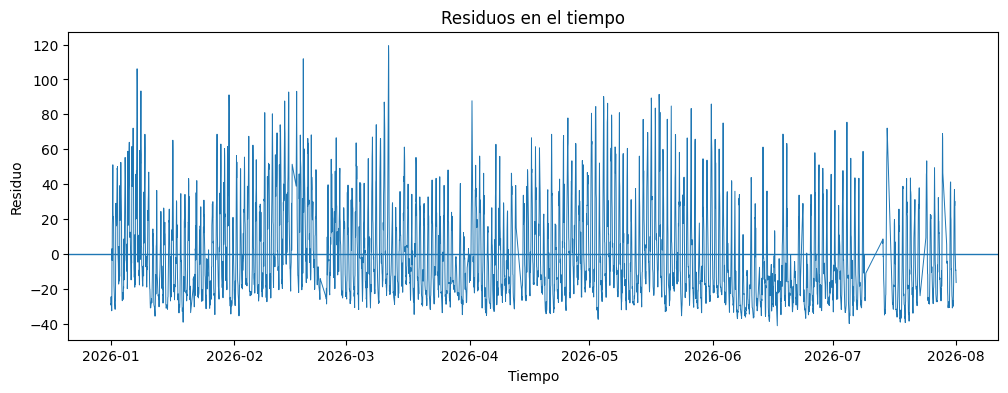

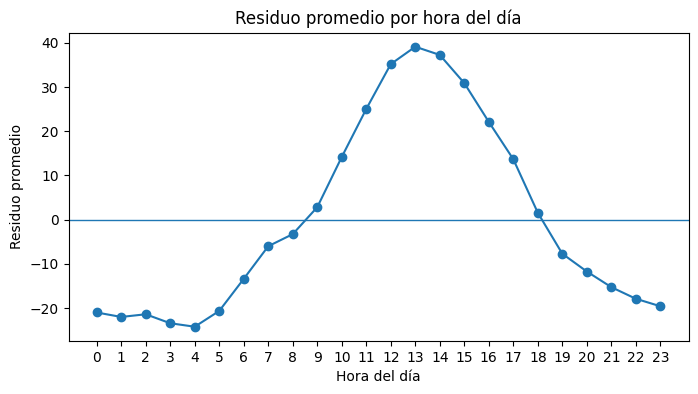

Durbin–Watson = 0.1939
Referencia: alrededor de 2 = poca autocorrelación; menor que 2 = positiva; mayor que 2 = negativa.


In [14]:

from statsmodels.stats.stattools import durbin_watson

plot_df = model_df[['datetime']].copy()
plot_df['residuo'] = resid.values
plot_df = plot_df.sort_values('datetime')

plt.figure(figsize=(12,4))
plt.plot(plot_df['datetime'], plot_df['residuo'], linewidth=0.7)
plt.axhline(0, linewidth=1)
plt.xlabel('Tiempo')
plt.ylabel('Residuo')
plt.title('Residuos en el tiempo')
plt.show()

plot_df['hora'] = plot_df['datetime'].dt.hour
mean_hour = plot_df.groupby('hora')['residuo'].mean()
plt.figure(figsize=(8,4))
plt.plot(mean_hour.index, mean_hour.values, marker='o')
plt.axhline(0, linewidth=1)
plt.xticks(range(24))
plt.xlabel('Hora del día')
plt.ylabel('Residuo promedio')
plt.title('Residuo promedio por hora del día')
plt.show()

dw = durbin_watson(resid)
print('Durbin–Watson =', round(dw, 4))
print('Referencia: alrededor de 2 = poca autocorrelación; menor que 2 = positiva; mayor que 2 = negativa.')


## e) QQ-plot de los residuos

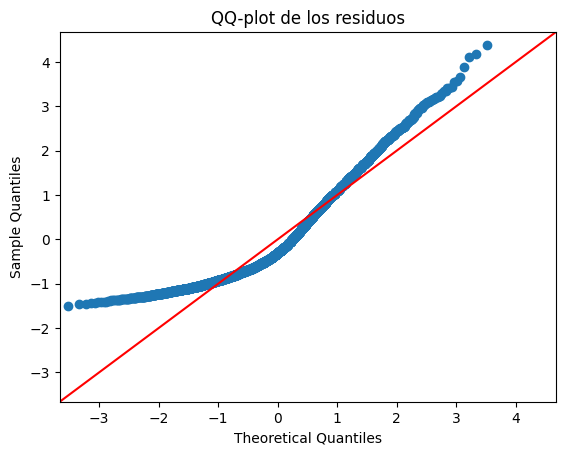

In [15]:

sm.qqplot(resid, line='45', fit=True)
plt.title('QQ-plot de los residuos')
plt.show()


## f) ¿Qué supuestos se rompen? ¿Le creemos al coeficiente de NO2 y a su p-value?

In [16]:

no2_coef = model.params.get('NO2', np.nan)
no2_p = model.pvalues.get('NO2', np.nan)
bp_p = bp_out['LM p-value']
hetero = 'sí hay evidencia de heterocedasticidad' if bp_p < 0.05 else 'no se detecta heterocedasticidad significativa'
auto = ('hay indicios de autocorrelación positiva' if dw < 1.5 else
        'hay indicios de autocorrelación negativa' if dw > 2.5 else
        'el valor está relativamente cerca de 2')
sig = 'es significativo al 5%' if no2_p < 0.05 else 'no es significativo al 5%'

texto = (
    f'El modelo explica aproximadamente {model.rsquared*100:.1f}% de la variación de O3. '
    f'Con Breusch–Pagan, {hetero}. El estadístico Durbin–Watson es {dw:.2f}, por lo que {auto}. '
    'El QQ-plot debe revisarse para valorar si la normalidad de los residuos es razonable, sobre todo en las colas. '
    f'Para NO2, el coeficiente estimado es {no2_coef:.4g} y {sig} (p={no2_p:.4g}). '
    'Sin embargo, NO, NO2 y NOX están fuertemente relacionados; si sus VIF son altos, existe multicolinealidad y los coeficientes y p-values pueden ser inestables. '
    'Por eso, el coeficiente de NO2 y su p-value no deben interpretarse de forma aislada.'
)
print(texto)


El modelo explica aproximadamente 25.4% de la variación de O3. Con Breusch–Pagan, sí hay evidencia de heterocedasticidad. El estadístico Durbin–Watson es 0.19, por lo que hay indicios de autocorrelación positiva. El QQ-plot debe revisarse para valorar si la normalidad de los residuos es razonable, sobre todo en las colas. Para NO2, el coeficiente estimado es 0.6871 y no es significativo al 5% (p=0.3855). Sin embargo, NO, NO2 y NOX están fuertemente relacionados; si sus VIF son altos, existe multicolinealidad y los coeficientes y p-values pueden ser inestables. Por eso, el coeficiente de NO2 y su p-value no deben interpretarse de forma aislada.
